# 이진 분류 실험 ⑦ — 트리 피처 조건 비교 (tree ablations)
06 에서 트리(XGBoost 0.639) 가 GINe(0.583) 를 넘어섰으므로, **서비스용 피처 셋은 트리로 결정**한다. GNN 은 안 돌린다 (조건당 트리 2개 ≈ 80분).

| 조건 | 피처 | 묻는 것 |
|---|---|---|
| `base06` | 기본 4 + pair 4 + 활동 8 + 이력 12 (28) | 06 재현 (기준선) |
| `amtseen` | base06 + `src/dst_amount_seen` (30) | v10 최강 무패턴 신호(ACH AUC 0.89) 의 효과. 데이터 생성 규칙 의존 의심이라 서비스 채택은 별도 판단 |
| `no_pf` | base06 − `payment_format` (27) | 지름길 제거 — 패턴 양성 100% ACH. 빠지는 만큼이 "결제수단 없이의 정직한 성능" |
| `tod` | base06 − `timestamp` + `hour_sin`, `hour_cos`, `weekday` (30) | 절대 시각(학습 구간 밖으로 외삽, 서비스에서 무의미) 을 반복 성분으로 교체 |

조건은 같은 z-norm 행렬(전체 33열 memmap) 의 **열 부분집합**이라 데이터 준비는 한 번. 결과는 `results/HI-Large/tree_ablations/<조건>/` 에 06 과 같은 형식(compare.csv, 점수 parquet, 패턴·차수 분석) 으로 저장하고 마지막에 한 표로 모은다.

**메모리**: 06 파이프라인 그대로 (피처 parquet 먼저, tx 열 단위 적재, float16, memmap z-norm, `train_trees_lowmem`). 그래프 없음 → 피크 15GB 안쪽

## 0. 작업 준비

In [1]:
import sys, json, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd()))
import bc_lib as B
L = B.L

In [2]:
# ---- 실험 설정 ------------------------------------------------------------
RUN_NAME = 'tree_ablations'
cfg = B.Config(dataset='HI-Large', smoke=False)
B.seed_all(cfg.seed)
OUT_DIR = cfg.out_dir(RUN_NAME)

PAIR_FEATURES = ['pair_prior_count', 'pair_gap_minutes', 'pair_count_1h', 'reverse_history_count']
ACT_FEATURES  = ['src_out_1h', 'src_out_1d', 'src_uniq_dst_1d', 'src_out_amt_1d', 'dst_in_1h', 'dst_in_1d', 'dst_uniq_src_1d', 'dst_in_amt_1d']
HIST_FEATURES = ['src_hist_out', 'src_hist_uniq_out', 'src_active_days', 'src_rate_vs_prior', 'src_minute_burst', 'src_gap_minutes',
                 'dst_hist_in', 'dst_hist_uniq_in', 'dst_active_days', 'dst_rate_vs_prior', 'dst_minute_burst', 'dst_gap_minutes']
AMT_SEEN      = ['src_amount_seen', 'dst_amount_seen']
TOD_FEATURES  = ['hour_sin', 'hour_cos', 'weekday']
PATHS = {'pair': cfg.feat_dir / 'pair_history.parquet', 'act': cfg.feat_dir / 'account_activity.parquet',
         'hist': cfg.feat_dir / 'account_history.parquet', 'tod': cfg.feat_dir / 'time_of_day.parquet'}
for k in ('pair', 'act', 'hist'):
    assert PATHS[k].exists(), f'앞 단계 parquet 이 없다: {PATHS[k]}'

BASE06 = B.BASIC_EDGE_FEATURES + PAIR_FEATURES + ACT_FEATURES + HIST_FEATURES
CONDITIONS = {
    'base06':  BASE06,
    'amtseen': BASE06 + AMT_SEEN,
    'no_pf':   [c for c in BASE06 if c != 'payment_format'],
    'tod':     [c for c in BASE06 if c != 'timestamp'] + TOD_FEATURES,
}
ALL_FEATURES = B.BASIC_EDGE_FEATURES + TOD_FEATURES + PAIR_FEATURES + ACT_FEATURES + HIST_FEATURES + AMT_SEEN   # z-norm 행렬 열 순서 (33)
{k: len(v) for k, v in CONDITIONS.items()}, len(ALL_FEATURES)

({'base06': 28, 'amtseen': 30, 'no_pf': 27, 'tod': 30}, 33)

## 1. 시간대 피처 — `time_of_day.parquet` (tx 올리기 전에)
거래 시각에서 하루 중 시간(sin/cos, 24h 주기) 과 요일(0=월). 절대 시각과 달리 학습·테스트 구간에서 같은 범위

In [3]:
con = L.connect(threads=8, memory='12GB')
currency_codes, format_codes = B.code_tables(con, cfg)
if not PATHS['tod'].exists():
    t0 = time.time()
    con.execute(f"""
        COPY (
            SELECT edge_id,
                   sin(2 * pi() * (hour(ts) * 60 + minute(ts)) / 1440.0)::FLOAT AS hour_sin,
                   cos(2 * pi() * (hour(ts) * 60 + minute(ts)) / 1440.0)::FLOAT AS hour_cos,
                   ((dayofweek(ts) + 6) % 7)::FLOAT                            AS weekday      -- DuckDB 는 일요일=0 → 월요일=0 으로
            FROM read_parquet({L.q(cfg.tx_path)}) ORDER BY edge_id
        ) TO {L.q(PATHS['tod'])} (FORMAT PARQUET, COMPRESSION ZSTD)""")
    print(f"{PATHS['tod'].name} 생성 {time.time()-t0:.0f}s")
con.execute(f"SELECT weekday, count(*) n, avg(hour_sin) s, avg(hour_cos) c FROM read_parquet({L.q(PATHS['tod'])}) GROUP BY 1 ORDER BY 1").df()

,weekday,n,s,c
0,0.0,29563150,0.004029,0.067521
1,1.0,27025441,0.001874,0.030170
2,2.0,29382057,0.007027,0.107188
3,3.0,27021581,0.001949,0.030191
4,4.0,41852878,0.004952,0.075480
5,5.0,11635747,0.004555,0.069491
6,6.0,13221225,0.003859,0.061470


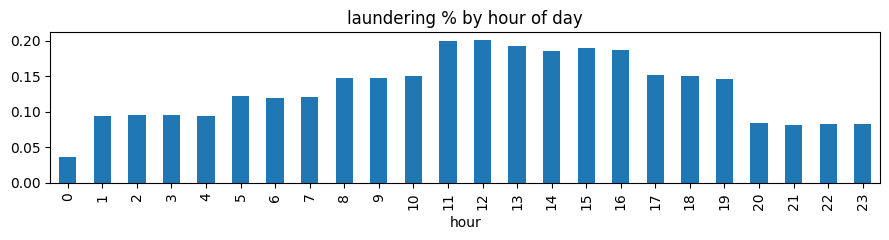

In [4]:
# 시간대별 세탁 비율 — 시간대 피처에 신호가 있나 (tx 적재 전에 DuckDB 로)
con.execute(f"""
    SELECT hour(ts) AS hour, count(*) AS n, avg(is_laundering::INT)::FLOAT * 100 AS laundering_pct
    FROM read_parquet({L.q(cfg.tx_path)}) GROUP BY 1 ORDER BY 1""").df().set_index('hour')['laundering_pct'].plot(kind='bar', figsize=(9, 2.5), title='laundering % by hour of day'); plt.tight_layout(); plt.show()

## 2. 데이터 준비 — tx + 피처 parquet 전부 (33열)

In [5]:
con.close(); con = L.connect(threads=8, memory='3GB')
con.register('currency_codes', currency_codes); con.register('format_codes', format_codes)
tx = B.load_tx_lowmem(con, cfg)                                              # 기본 9열 (port 없음 — 트리는 안 씀)
B.trim('(tx 적재 후)')
tx = B.attach_parquet(tx, PATHS['tod'],  TOD_FEATURES,            dtype=np.float16)
tx = B.attach_parquet(tx, PATHS['pair'], PAIR_FEATURES,           dtype=np.float16)
tx = B.attach_parquet(tx, PATHS['act'],  ACT_FEATURES,            dtype=np.float16)
tx = B.attach_parquet(tx, PATHS['hist'], HIST_FEATURES + AMT_SEEN, dtype=np.float16)
B.trim('(피처 붙인 후)'); tx.shape

RSS 7.9 GB (tx 적재 후)
RSS 18.7 GB (피처 붙인 후)


(179702079, 38)

In [6]:
tx.groupby('y')[TOD_FEATURES + AMT_SEEN].mean().T.rename(columns={0: 'normal', 1: 'laundering'})

y,normal,laundering
hour_sin,0.004208,-0.066863
hour_cos,0.064637,-0.192038
weekday,2.624900,2.943732
src_amount_seen,0.896240,0.105907
dst_amount_seen,0.896136,0.105978


## 3. z-norm (학습 구간 통계) + 표본 — 한 번

In [7]:
in_train = B.window_mask(tx, cfg.train_window)
FEAT_PATH = cfg.feat_dir / f'feat16_{RUN_NAME}.npy'
feat_z, znorm_table = B.znorm_features(tx, ALL_FEATURES, in_train, out_path=FEAT_PATH)   # 33열 memmap. tx 에서 피처 열은 떨어짐
B.trim('(z-norm 후)'); znorm_table

RSS 6.2 GB (z-norm 후)


,feature,mean(train),std(train)
0,timestamp,3.036519e+06,1.403026e+06
1,amount_received,5.573174e+06,1.804616e+09
2,received_currency,8.450158e+00,4.231340e+00
3,payment_format,2.946519e+00,1.430707e+00
4,hour_sin,5.078882e-03,6.791958e-01
5,hour_cos,7.766914e-02,7.298431e-01
6,weekday,2.640175e+00,1.758778e+00
7,pair_prior_count,3.619805e+00,1.249467e+00
8,pair_gap_minutes,4.934153e+00,3.020589e+00
9,pair_count_1h,3.837265e-01,4.403188e-01


In [8]:
val_df = B.val_sample(con, cfg.val_window, cfg.val_neg_rate)
test_df = B.test_full(con, cfg.test_window)
in_degree = B.recipient_indegree(con, cfg)
con.close()
all_edge_ids = tx['edge_id'].to_numpy()
val_idx = B.rows_of(all_edge_ids, val_df['edge_id'].to_numpy()); test_idx = B.rows_of(all_edge_ids, test_df['edge_id'].to_numpy())
assert (tx['y'].to_numpy()[val_idx] == val_df['y'].to_numpy()).all()
del all_edge_ids
train_rows = np.flatnonzero(in_train); y_train = tx['y'].to_numpy()[in_train]
y_val, w_val = val_df['y'].to_numpy(), val_df['w'].to_numpy()
del tx; gc.collect(); B.trim('(tx 삭제 후)')
len(train_rows), val_df.shape, test_df.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

RSS 3.9 GB (tx 삭제 후)


(102336629, (521382, 7), (26808230, 5))

## 4. 조건별 학습 — 열 부분집합만 바꿔서
조건마다 `results/HI-Large/tree_ablations/<조건>/` 에 compare.csv · results.json · 점수 parquet · 패턴/차수/컷 분석을 저장. 이미 끝난 조건(compare.csv 있음) 은 건너뛴다

In [9]:
def run_condition(name, feats):
    out = OUT_DIR / name; out.mkdir(exist_ok=True)
    if (out / 'compare.csv').exists():
        print(f'[{name}] 이미 완료 — 건너뜀'); return
    B.log(f'[{name}] 피처 {len(feats)}')
    cols = [ALL_FEATURES.index(c) for c in feats]
    X_val = B.rows_matrix(feat_z, val_idx, cols)
    test_pred = lambda m: B.predict_rows(m, feat_z, test_idx, cols)
    results = {}
    lgb_model, xgb_model = B.train_trees_lowmem(feat_z, train_rows, cols, y_train, X_val, y_val, w_val, test_pred, val_df, test_df, cfg, results)
    models = [('xgboost', xgb_model), ('lightgbm', lgb_model)]
    imp = pd.DataFrame({'feature': feats, 'xgboost_gain': [xgb_model.get_booster().get_score(importance_type='gain').get(f'f{i}', 0.0) for i in range(len(feats))],
                        'lightgbm_gain': lgb_model.booster_.feature_importance('gain')})
    imp.sort_values('xgboost_gain', ascending=False).to_csv(out / 'importance.csv', index=False, encoding='utf-8-sig')
    pattern_tables, degree_tables, cut_tables = [], [], []
    for mname, model in models:
        sc = pd.DataFrame(dict(edge_id=test_df.edge_id, y=test_df.y, score=test_pred(model)))
        sc.to_parquet(out / f'{mname}_test_scores.parquet', index=False)
        pattern_tables.append(B.pattern_recall(sc).assign(model=mname))
        degree_tables.append(B.degree_stratified(sc, test_df['dst'].to_numpy(), in_degree).assign(model=mname))
        cut_tables.append(B.cut_table(sc).assign(model=mname))
    pd.concat(pattern_tables).to_csv(out / 'analysis_pattern.csv', encoding='utf-8-sig')
    pd.concat(degree_tables).to_csv(out / 'analysis_degree.csv', encoding='utf-8-sig')
    pd.concat(cut_tables).to_csv(out / 'analysis_cuts.csv', encoding='utf-8-sig')
    B.save_results(out, cfg, results, features=dict(tree=feats))
    del X_val, lgb_model, xgb_model; gc.collect(); B.trim(f'[{name}] 끝')

for name, feats in CONDITIONS.items():
    run_condition(name, feats)

[12:32:05] [base06] 피처 28
[13:09:42] lightgbm val AP 0.6460  (best_it 381)
RSS 4.1 GB (lightgbm 후)
[13:48:50] xgboost  val AP 0.6505  (best_it 437)
RSS 4.3 GB (xgboost 후)
RSS 4.8 GB [base06] 끝
[13:58:11] [amtseen] 피처 30
[14:38:54] lightgbm val AP 0.6515  (best_it 494)
RSS 4.7 GB (lightgbm 후)
[14:47:00] xgboost  val AP 0.6263  (best_it 35)
RSS 4.7 GB (xgboost 후)
RSS 5.1 GB [amtseen] 끝
[14:54:47] [no_pf] 피처 27
[15:40:03] lightgbm val AP 0.6409  (best_it 498)
RSS 4.7 GB (lightgbm 후)
[16:14:17] xgboost  val AP 0.6365  (best_it 349)
RSS 4.7 GB (xgboost 후)
RSS 5.1 GB [no_pf] 끝
[16:23:42] [tod] 피처 30
[17:07:25] lightgbm val AP 0.6488  (best_it 500)
RSS 4.7 GB (lightgbm 후)
[17:52:33] xgboost  val AP 0.6507  (best_it 474)
RSS 4.7 GB (xgboost 후)
RSS 5.1 GB [tod] 끝


## 5. 조건 비교

In [10]:
# 전체 지표 — 조건 × 모델 (테스트)
rows = []
for name in CONDITIONS:
    c = pd.read_csv(OUT_DIR / name / 'compare.csv', index_col=[0, 1])
    for model in c.index.get_level_values(0).unique():
        t = c.loc[(model, 'test')]; v = c.loc[(model, 'val')]
        rows.append(dict(condition=name, model=model, n_feat=len(CONDITIONS[name]), val_AP=v['AP'], test_AP=t['AP'], F1=t['F1'], F1_at_0_5=t['F1_at_0.5'],
                         precision=t['precision'], recall=t['recall'], recall_1pct=t['recall_at_1pct'], unmatched_1pct=t['unmatched_recall_at_1pct']))
summary = pd.DataFrame(rows).set_index(['model', 'condition']).sort_index()
summary.to_csv(OUT_DIR / 'summary.csv', encoding='utf-8-sig'); summary.round(4)

n_feat  val_AP  test_AP      F1  F1_at_0_5  precision  \
model    condition                                                          
lightgbm amtseen        30  0.6515   0.6421  0.6776     0.6464     0.8295   
         base06         28  0.6460   0.6341  0.6722     0.6379     0.8178   
         no_pf          27  0.6409   0.5050  0.5787     0.1547     0.8035   
         tod            30  0.6488   0.6360  0.6739     0.6362     0.8239   
xgboost  amtseen        30  0.6263   0.6060  0.6537     0.6440     0.7926   
         base06         28  0.6505   0.6393  0.6767     0.6514     0.8372   
         no_pf          27  0.6365   0.5027  0.5748     0.1310     0.7818   
         tod            30  0.6507   0.6343  0.6761     0.6387     0.8313   

                    recall  recall_1pct  unmatched_1pct  
model    condition                                       
lightgbm amtseen    0.5727       0.8199          0.5656  
         base06     0.5706       0.8129          0.5491  
         no_pf      0.4521       0.6049          0.0928  
         tod        0.5701       0.8057          0.5321  
xgboost  amtseen    0.5562       0.8128          0.5499  
         base06     0.5679       0.8107          0.5439  
         no_pf      0.4545       0.5979          0.0893  
         tod        0.5698       0.7926          0.5009

In [11]:
# 패턴별 recall@1% 과 argmax — 조건별 (XGBoost)
pat = pd.concat([pd.read_csv(OUT_DIR / n / 'analysis_pattern.csv', index_col=0).query("model == 'xgboost'").assign(condition=n) for n in CONDITIONS])
order = [p for p in B.PATTERN_ORDER + ['ALL'] if p in pat.index]
display(pat.reset_index().pivot(index='pattern_type', columns='condition', values='recall').loc[order, list(CONDITIONS)].round(4))
pat.reset_index().pivot(index='pattern_type', columns='condition', values='argmax').loc[order, list(CONDITIONS)].round(4)

condition,base06,amtseen,no_pf,tod
pattern_type,,,,
FAN-OUT,0.9995,0.9977,0.9648,0.9995
FAN-IN,1.0000,1.0000,0.9709,0.9995
GATHER-SCATTER,0.9995,0.9987,0.9651,0.9995
SCATTER-GATHER,0.9995,0.9977,0.9689,0.9992
CYCLE,0.9989,0.9989,0.9460,0.9984
RANDOM,0.9985,1.0000,0.9543,0.9985
BIPARTITE,0.9995,0.9995,0.9334,0.9989
STACK,0.9985,0.9988,0.9447,0.9971
UNMATCHED,0.5439,0.5499,0.0893,0.5009


condition,base06,amtseen,no_pf,tod
pattern_type,,,,
FAN-OUT,0.9822,0.9686,0.9653,0.9808
FAN-IN,0.9776,0.9651,0.9719,0.9807
GATHER-SCATTER,0.9760,0.9638,0.9654,0.9802
SCATTER-GATHER,0.9807,0.9686,0.9704,0.9815
CYCLE,0.9541,0.9261,0.9477,0.9638
RANDOM,0.9581,0.9213,0.9573,0.9618
BIPARTITE,0.9405,0.8849,0.9384,0.9536
STACK,0.9456,0.9110,0.9470,0.9578
UNMATCHED,0.0907,0.0771,0.0905,0.0920


In [12]:
# 수신 계좌 in-degree 구간별 AP — 조건별 (XGBoost)
deg = pd.concat([pd.read_csv(OUT_DIR / n / 'analysis_degree.csv', index_col=0).query("model == 'xgboost'").assign(condition=n) for n in CONDITIONS])
deg.reset_index().pivot(index='bin', columns='condition', values='AP')[list(CONDITIONS)].round(4)

condition,base06,amtseen,no_pf,tod
bin,,,,
[1-4],0.7046,0.5732,0.7121,0.7002
[10-19],0.6283,0.5958,0.5180,0.6240
[100+],0.6513,0.6209,0.5173,0.6449
[20-49],0.5609,0.5288,0.4459,0.5564
[5-9],0.8197,0.7800,0.7193,0.8174
[50-99],0.5689,0.5350,0.4595,0.5640


In [13]:
# 피처 중요도 — 조건별 상위 10 (XGBoost gain)
for n in CONDITIONS:
    imp = pd.read_csv(OUT_DIR / n / 'importance.csv')
    print(f'--- {n}'); print(imp.head(10).to_string(index=False))

--- base06
              feature  xgboost_gain  lightgbm_gain
     pair_prior_count   3387.250000   1.505662e+06
       payment_format   3160.264648   3.454465e+06
     src_minute_burst   2648.265625   7.094786e+06
      src_uniq_dst_1d   1063.707642   3.800002e+05
           src_out_1h    578.954651   9.447632e+04
           src_out_1d    566.400024   8.120372e+04
    src_hist_uniq_out    552.953796   1.752215e+06
      dst_gap_minutes    491.218933   6.527951e+05
reverse_history_count    336.832153   2.161886e+06
            dst_in_1h    305.739594   3.326816e+05
--- amtseen
              feature  xgboost_gain  lightgbm_gain
      src_amount_seen  90730.734375   2.580746e+06
     pair_prior_count  20843.203125   4.722148e+05
     src_minute_burst  19206.384766   7.109779e+06
       payment_format  17786.640625   2.161706e+06
      dst_gap_minutes   4679.312500   7.019255e+05
      src_uniq_dst_1d   3188.745117   3.689881e+05
           src_out_1d   2351.457275   1.825726e+05
    src_

In [14]:
# 운영점 — argmax 와 r@0.1% 에서 조건별 precision / recall (XGBoost)
cuts = pd.concat([pd.read_csv(OUT_DIR / n / 'analysis_cuts.csv', index_col=0).query("model == 'xgboost'").assign(condition=n) for n in CONDITIONS])
cuts.loc[['r@0.1%', 'r@1%', 'argmax']].reset_index().pivot(index='cut', columns='condition', values=['precision', 'recall']).round(4)

precision                          recall                        
condition   amtseen  base06   no_pf     tod amtseen  base06   no_pf     tod
cut                                                                        
argmax       0.7173  0.7075  0.0735  0.6736  0.5843  0.6035  0.5994  0.6073
r@0.1%       0.7396  0.7621  0.6376  0.7606  0.5754  0.5929  0.4961  0.5917
r@1%         0.1045  0.1042  0.0769  0.1019  0.8128  0.8107  0.5979  0.7926

## 6. 읽는 법
- `amtseen` − `base06`: 과거 동일 금액 신호의 몫. 크게 오르면 "AMLworld 안에서는 유효" 지만 서비스 채택은 외부 데이터 검증 후
- `base06` − `no_pf`: 결제수단 지름길의 몫. 이 차이만큼은 다른 데이터에서 사라질 수 있는 성능
- `tod` vs `base06`: 같거나 높으면 timestamp 를 시간대로 바꿔도 손해 없음 → 서비스 피처는 `tod` 기준
- 서비스 후보 피처 셋 = `tod` (+ `no_pf` 결과에 따라 결제수단 유지/제거 결정)